In [2]:
using NPZ,Interpolations,Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot


┌ Warning: Error requiring `MakieCore` from `Polynomials`
│   exception = (LoadError("/Users/nmt121/.julia/packages/Polynomials/6i39P/ext/PolynomialsMakieCoreExt.jl", 1, ArgumentError("Package Polynomials does not have MakieCore in its dependencies:\n- If you have Polynomials checked out for development and have\n  added MakieCore as a dependency but haven't updated your primary\n  environment's manifest file, try `Pkg.resolve()`.\n- Otherwise you may need to report an issue with Polynomials")), Union{Ptr{Nothing}, Base.InterpreterIP}[Ptr{Nothing} @0x000000010d026eee, Ptr{Nothing} @0x000000010b38c9bf, Ptr{Nothing} @0x000000010b3bda0c, Ptr{Nothing} @0x000000010b3bce62, Ptr{Nothing} @0x000000010b3bca65, Ptr{Nothing} @0x000000010b3bd104, Ptr{Nothing} @0x000000010b3bdc34, Ptr{Nothing} @0x000000012055fd67, Ptr{Nothing} @0x000000010b38c9bf, Ptr{Nothing} @0x000000012045028a, Ptr{Nothing} @0x000000012044fd62, Ptr{Nothing} @0x000000010b38c9bf, Ptr{Nothing} @0x000000010b399259, Ptr{Nothing} @0x0

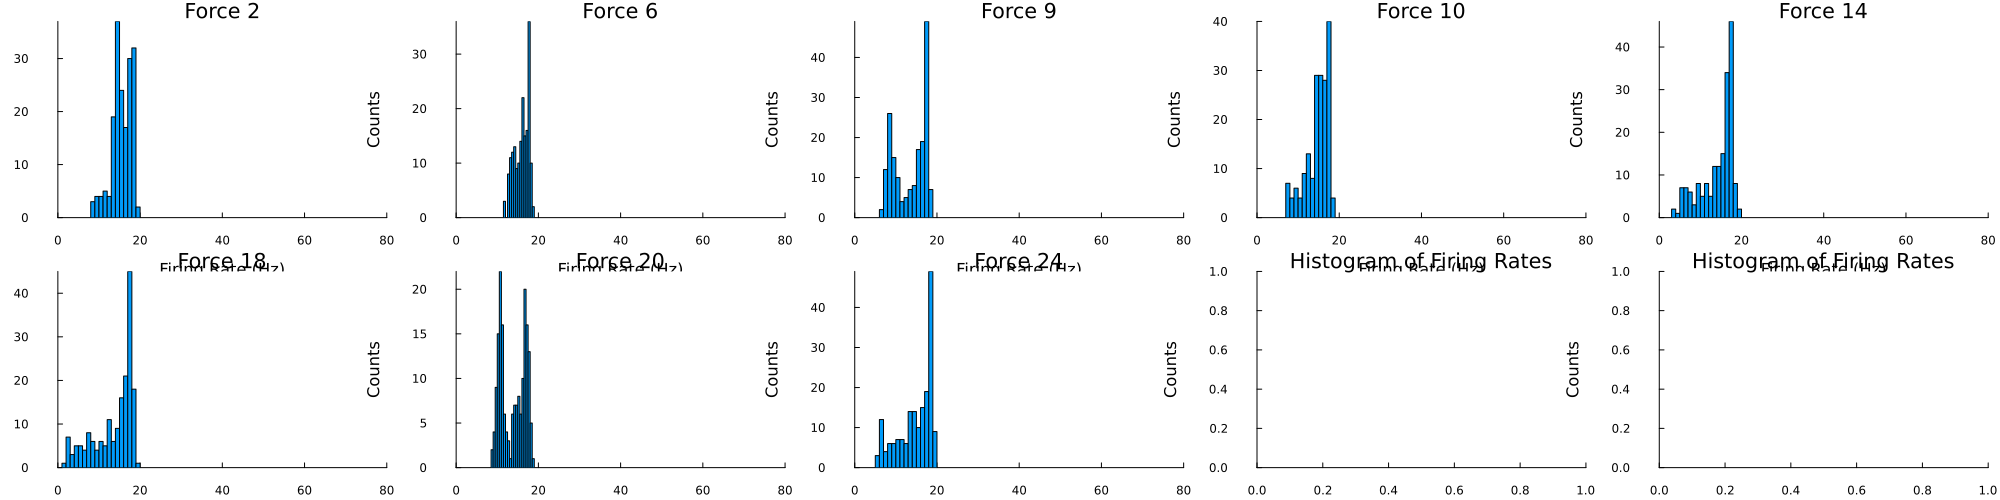

In [42]:
# Set sampling rate
sampling_rate = 20000  # Hz

# List of force conditions
############## S1 ##############
# force_conditions = [ 1,6,9,11,14,17,21,24,27,30] 
# force_conditions = [ 3,4,9,11,14,18,21,23,26,29]
# force_conditions = [1,6,9,10,13,17,20,23,25,29,30]
# force_conditions = [1,5,9,10,13,18,21,23,26,28]
# force_conditions = [3,5,9,10,14,18,21,22,26,30]
# force_conditions = [1,5,9,10,14,18,19,23,26,28]
# force_conditions = [3,7,12,13,17,21,23,25,30]
# force_conditions = [1,4,8,9,13,15,18,23,26,27]
# force_conditions = [1,5,7,10,15,19,22,25,30]
# force_conditions = [3,4,8,12,15,18,20,24,25,28]
# force_conditions = [2,4,7,12,15,17,20,24,28]
# force_conditions = [1,5,9,12,14,16,19,23,25,30]
# force_conditions = [3,5,8,12,15,18,19,22,26,28]
# force_conditions = [3,5,8,12,15,18,19,22,26,28]

############## S2 ##############
force_conditions = [2,6,9,10,14,18,20,24]




# Create a figure with subplots (4 columns)
n_plots = length(force_conditions)
n_rows = ceil(Int, n_plots / 5)  # Calculate the number of rows based on 4 columns

# Create a plot grid with 4 columns
p = Plots.plot(legend=false, grid=false, xlabel="Firing Rate (Hz)", ylabel="Counts", title="Histogram of Firing Rates", layout=(n_rows, 5), size=(2000, 500))

# Loop through each force condition
for (i, force) in enumerate(force_conditions)
    day_str = lpad(force, 2, '0')  # Format day number with leading zero
    
    # Construct the file path for the current force condition
    force_file = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S2_alltrials/Day02/DR_S2_Day02_trial$(day_str).jld2"


    # Load the spike array for the current force condition
    JLD2.@load force_file spike_array

    # Initialize array for storing firing rates for this file
    all_rates = []

    # Calculate rates for each motor unit
    # Initialize array for storing average firing rates (one per motor unit)
    avg_rates_per_neuron = Float64[]

    for mn in 1:size(spike_array, 1)
        spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
        if length(spike_pos) > 1
            ISIs = diff(spike_pos) ./ sampling_rate  # ISIs in seconds
            avg_rate = 1 / mean(ISIs)  # Hz
            if avg_rate <= 80  # 
                push!(avg_rates_per_neuron, avg_rate)
            end
        end
    end

    println(avg_rates_per_neuron)

    save_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/new/Day1/force$(force)_firing_rates.jld2"


    JLD2.@save save_path avg_rates_per_neuron

    if !isempty(avg_rates_per_neuron)
        histogram!(p, avg_rates_per_neuron,bins=20,
            normalize=false,
            xlabel="Firing Rate (Hz)",
            ylabel="Counts",
            title="Force $force",
            subplot=i,
            xlim=[0, 80])
    else
        println("Warning: No valid firing rates for force $force")
    end

end

# Show the plot
display(p)
